<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">

# **Visión por Computadora 3D**
# **Clase 3, Vóxeles y CNN 3D**


1. voxelizamos objetos reales de ModelNet40
2. medimos cuánto de la grilla queda vacío en un escaneo LiDAR real de KITTI
3. entrenamos una CNN 3D densa
4. entrenamos una CNN 3D dispersa con spconv, la librería que usan los detectores para autos

Usaremos **spconv**:
* es una librería para PyTorch que hace convoluciones 3D solo donde hay datos
* una CNN 3D normal recorre todos los cubos de la grilla, incluso los vacíos, y en una escena real más del 99 % está vacía
* spconv guarda solo la lista de cubos ocupados, con su posición y su valor, y calcula únicamente sobre ellos
* asi gastamos mucha menos memoria y tiempo, y permite usar grillas más finas

usaremos dos tipos de capa:

* SubMConv3d: convoluciona solo sobre los cubos ocupados y no crea cubos nuevos, así que la forma del objeto no se “infla”
* SparseConv3d con stride 2: reduce la resolución a la mitad, como un pooling

---
## **1.- Importamos e instalamos lo necesario**

In [ ]:
import torch
import os

CUMM_DISABLE_JIT y SPCONV_DISABLE_JIT = "1", le dicen a spconv que use su versión ya compilada en lugar de compilar en Colab ya que tarda mucho

In [ ]:
os.environ["CUMM_DISABLE_JIT"] = os.environ["SPCONV_DISABLE_JIT"] = "1"

Leemos la versión de CUDA instalada y la convertimos a tupla

In [ ]:
cuda = tuple(map(int, torch.version.cuda.split(".")))

Según la versión se elige el paquete correcto

In [ ]:
spconv_pkg = "spconv-cu126" if cuda >= (12, 6) else "spconv-cu124" if cuda >= (12, 4) else "spconv-cu121"

Instalamos lo necesario

In [ ]:
!pip install -q {spconv_pkg}
!pip install -q --force-reinstall --no-deps {spconv_pkg} "{spconv_pkg.replace('spconv', 'cumm')}<0.8"

Importamos lo necesario

In [ ]:
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import spconv.pytorch as spconv

Importamos lo necesario para abrir, buscar y leer archivos

In [ ]:
import zipfile
import glob
import h5py
from huggingface_hub import hf_hub_download

Esto descarga el zip del repositorio de datasets y devuelve la ruta local

In [ ]:
zipfile.ZipFile(hf_hub_download("Msun/modelnet40", "modelnet40_ply_hdf5_2048.zip", repo_type="dataset")).extractall(".")

modelnet40_ply_hdf5_2048.zip: reconstructing file:   0%|          |  0.00B /  435MB            

modelnet40_ply_hdf5_2048.zip: downloading bytes:           |  0.00B            

la siguiente función:
* recibe train o test
* busca todos los archivos de ese conjunto y los ordena
* lee la clave "data" y se queda con los primeros 1024 puntos (esto es para ahorrar memoria y tiempo, después lo vamos a voxelizar por lo que no se pierde mucha informacion)
* lee las etiquetas y las aplana
* al final todo se convierte a tensores de pytorch y los manda a la gpu, se vuelve long para cross entropy

In [ ]:
def leer(split):
    archivos = sorted(glob.glob(f"modelnet40_ply_hdf5_2048/ply_data_{split}*.h5"))
    X = np.concatenate([h5py.File(f)["data"][:, :1024] for f in archivos])
    y = np.concatenate([h5py.File(f)["label"][:].ravel() for f in archivos])
    return torch.tensor(X).cuda(), torch.tensor(y).long().cuda()

cargamos el conjunto de train y test

In [ ]:
Xtr, ytr = leer("train")
Xte, yte = leer("test")

leemos el archivo con los 40 nombres y los separamos en una lista, la posición en la lista corresponde al numero de etiqueta

In [ ]:
CLASES = open("modelnet40_ply_hdf5_2048/shape_names.txt").read().split()
print("entrenamiento:", tuple(Xtr.shape), "| test:", tuple(Xte.shape))

entrenamiento: (9840, 1024, 3) | test: (2468, 1024, 3)


## **2.- Voxelizar**

esta función recibe:
* P, un lote de B objetos con N puntos de 3 coordenadas cada uno
* R, cantidad de cubos por lado

devuelve una grilla por objeto

In [ ]:
def voxelizar(P, R):
    '''
    Calcula en qué cubo cae cada punto, en tres pasos:
      (P + 1) / 2 lleva las coordenadas de [−1, 1] a [0, 1]
      * R las lleva a [0, R]
      .long() quita los decimales y deja el número de cubo, como los valores ya no son negativos, equivale a redondear hacia abajo
      .clamp(0, R - 1) cubre el caso x = 1 exacto: daría R, que se sale de la grilla, y lo deja en el último cuboç

    i tiene la misma forma que P, (B, N, 3), pero guarda indices enteros en lugar de coordenadas
    '''
    i = ((P + 1) / 2 * R).long().clamp(0, R - 1)

    # crea la grilla vacía, toda en ceros, en el mismo dispositivo que los puntos (la GPU)
    V = torch.zeros(len(P), 1, R, R, R, device=P.device)

    '''
    Cuando hay varios objetos en el lote, b le indica a cada punto en qué grilla
    escribir, así los puntos del objeto 0 van a V[0] y los del objeto 1 a V[1],
    todo en una sola línea y sin bucles
    '''
    b = torch.arange(len(P), device=P.device)[:, None]

    # pone un 1 en el cubo donde cae cada punto de cada objeto, todos a la vez y sin bucles
    V[b, 0, i[..., 0], i[..., 1], i[..., 2]] = 1
    return V

recorremos cuatro resoluciones

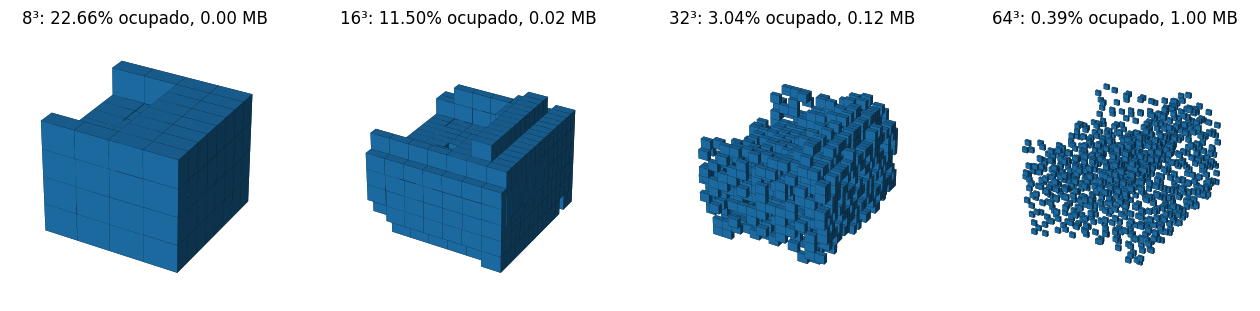

In [ ]:
fig = plt.figure(figsize=(16, 4))
for k, R in enumerate([8, 16, 32, 64]):
    V = voxelizar(Xtr[:1], R)[0, 0].cpu().numpy().astype(bool)
    ax = fig.add_subplot(1, 4, k + 1, projection="3d"); ax.set_axis_off()
    ax.voxels(V.transpose(0, 2, 1), edgecolor="k", linewidth=0.05)
    ax.set_title(f"{R}³: {V.mean():.2%} ocupado, {R**3 * 4 / 1024**2:.2f} MB")
plt.show()

* al duplicar R (resolución de la grilla, cuántos cubos hay por lado) la memoria se multiplica por 8. Como el objeto siempre tiene 1024 puntos, a alta resolución hay más cubos que puntos, así que el porcentaje ocupado cae y la superficie se “desarma” en cubitos aislados
* esta es la motivación para usar spconv después

## **3.- escaneo LiDAR real**


descargamos el escanero LIDAR de KITTI

In [ ]:
!wget -q -nc https://github.com/zhulf0804/PointPillars/raw/main/pointpillars/dataset/demo_data/val/000134.bin

lee el archivo, lo ordena en filas de 4 valores (x, y, z, reflectancia) y se queda con x, y, z

In [ ]:
scan = np.fromfile("000134.bin", dtype=np.float32).reshape(-1, 4)[:, :3]

define la caja que se va a analizar (70 m hacia adelante, 80 m de ancho, 4 m de alto) y vóxeles de 5 cm

In [ ]:
lo, hi, s = np.array([0, -40, -3]), np.array([70, 40, 1]), 0.05 #s = 0.05 define vóxeles de 5 cm

esto marca qué puntos caen dentro de esa caja

In [ ]:
dentro = np.all((scan >= lo) & (scan < hi), axis=1)

calcula en qué vóxel cae cada punto y cuenta cuántos vóxeles distintos quedan ocupados

In [ ]:
ocupados = len(np.unique(((scan[dentro] - lo) / s).astype(int), axis=0))

calcula cuántos vóxeles tiene la grilla completa: 1400 × 1600 × 80 ≈ 179 millones

In [ ]:
total = np.prod(((hi - lo) / s).astype(int))

In [ ]:
# vemos cuantos vóxeles están ocupados y qué porcentaje del total representan
print(f"{len(scan):,} puntos | {ocupados:,} de {total:,} vóxeles ocupados ({ocupados / total:.4%})")

# comparamos la memoria de guardar toda la grilla (unos 684 MB) con la de guardar solo los vóxeles ocupados (unos pocos MB)
print(f"grilla densa: {total * 4 / 1024**2:.0f} MB | solo los ocupados: {ocupados * 16 / 1024**2:.1f} MB")

19,097 puntos | 15,111 de 179,200,000 vóxeles ocupados (0.0084%)
grilla densa: 684 MB | solo los ocupados: 0.2 MB


recordemos que:
* la grilla densa en cuando se guarda un valor por cada cubo de la grilla, esté vacío o no
* solo los vóxeles ocupados (dispersa), se guarda una lista con la posición de los cubos que tienen algo, y nada más

## **3.- CNN 3D densa**

La misma idea que una CNN 2D con un eje más: filtros de 3 × 3 × 3 y pooling de 2 × 2 × 2. Voxelizamos cada lote al vuelo en la GPU.

Definimos una CNN 3D que clasifica objetos voxelizados a 32³ en 40 clases, la entrenamos 15 épocas y mide su accuracy, su tiempo y su memoria

esta función aumenta los datos, deforma un poco cada objeto en cada lote

In [ ]:
def aumentar(P):
    return (P * torch.empty(len(P), 1, 3, device=P.device).uniform_(0.8, 1.2)  # escala al azar por eje (80 % a 120 %), una silla puede quedar un poco más ancha o más alta
              + torch.empty(len(P), 1, 3, device=P.device).uniform_(-0.1, 0.1)).clamp(-1, 1)  # desplaza al azar y recorta a [-1, 1]


esta función realiza bucle de entrenamiento común para la red densa y la dispersa

In [ ]:
def entrenar(red, modulos, epocas=15, lote=32):
    opt = torch.optim.Adam(modulos.parameters(), lr=1e-3)
    torch.cuda.reset_peak_memory_stats() # reinicia el medidor de memoria
    t0 = time.time()
    for epoca in range(epocas):
        modulos.train()
        for b in torch.randperm(len(Xtr), device="cuda").split(lote): # mezcla los índices y los corta en lotes de 32
            perdida = F.cross_entropy(red(aumentar(Xtr[b])), ytr[b]) # aumenta, predice y calcula el error contra la etiqueta
            opt.zero_grad()
            perdida.backward()
            opt.step()

        modulos.eval()
        with torch.no_grad(): # sin gradientes: más rápido y usa menos memoria
            acc = torch.cat([red(x).argmax(1) for x in Xte.split(64)]).eq(yte).float().mean()  # predice el test y mide el accuracy
        print(f"época {epoca + 1:2d} | accuracy test {acc:.3f}")   # muestra la exactitud de esta época
    print(f"{(time.time() - t0) / epocas:.1f} s por época | memoria máxima {torch.cuda.max_memory_allocated() / 1024**2:.0f} MB")  # tiempo y memoria pico

bloque basico, compuesto por convolucion, normalización y reducción

In [ ]:
def bloque(cin, cout):
    return [nn.Conv3d(cin, cout, 3, padding=1),
            nn.BatchNorm3d(cout),
            nn.ReLU(),
            nn.MaxPool3d(2)]

tres bloques: 32³ -> 16³ -> 8³ -> 4³

In [ ]:
# los canales van creciendo mientras que la grilla se hace pequeña
cnn = nn.Sequential(*bloque(1, 32),
                    *bloque(32, 64),
                    *bloque(64, 128),
                    nn.AdaptiveMaxPool3d(1), # este es un MaxPool donde elegimos el tamaño de salida y la capa calcula sola el tamaño de la ventana
                    nn.Flatten(),
                    nn.Dropout(0.5),
                    nn.Linear(128, 40)).cuda()

recibe puntos, los voxeliza a 32³ y los pasa por la CNN

In [ ]:
densa = lambda P: cnn(voxelizar(P, 32))

entrena la red densa e imprime los resultados

In [ ]:
entrenar(densa, cnn)

época  1 | accuracy test 0.432
época  2 | accuracy test 0.595
época  3 | accuracy test 0.722
época  4 | accuracy test 0.780
época  5 | accuracy test 0.794
época  6 | accuracy test 0.783
época  7 | accuracy test 0.838
época  8 | accuracy test 0.832
época  9 | accuracy test 0.831
época 10 | accuracy test 0.836
época 11 | accuracy test 0.850
época 12 | accuracy test 0.857
época 13 | accuracy test 0.857
época 14 | accuracy test 0.858
época 15 | accuracy test 0.870
20.2 s por época | memoria máxima 1153 MB


**Predicciones de la CNN densa en 8 objetos de test**

tomamos 8 objetos de test al azar, los clasificamos con la red densa y dibuja cada uno en verde si acertó o en rojo si falló, con la clase real y las 3 clases más probables en el título

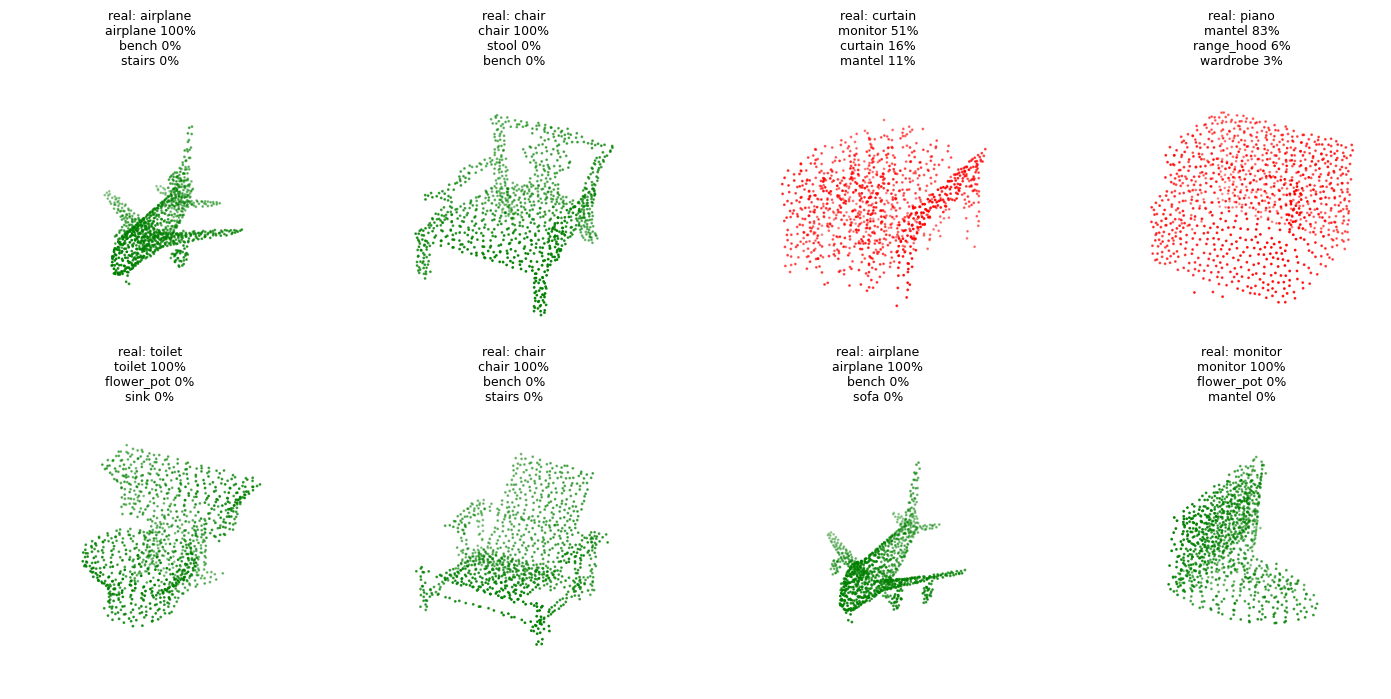

In [ ]:
cnn.eval()
ejemplos = torch.randperm(len(Xte))[:8] # elige 8 objetos de test al azar
with torch.no_grad():
    prob = F.softmax(densa(Xte[ejemplos]), dim=1) # predice y pasa los puntajes a probabilidades

fig = plt.figure(figsize=(18, 8))
for k, i in enumerate(ejemplos):
    p = Xte[i].cpu() # puntos del objeto, pasados a CPU para graficar
    top_p, top_c = prob[k].topk(3) # las 3 clases más probables y sus probabilidades
    acierto = top_c[0] == yte[i] # acierta si la clase más probable es la real
    ax = fig.add_subplot(2, 4, k + 1, projection="3d"); ax.set_axis_off()
    ax.scatter(p[:, 0], p[:, 2], p[:, 1], s=1, c="green" if acierto else "red")
    ax.set_title(f"real: {CLASES[yte[i]]}\n" + "\n".join(f"{CLASES[c]} {v:.0%}" for v, c in zip(top_p, top_c)), fontsize=9)
plt.show()

**Grad-CAM 3D**

este bloque usa Grad-CAM para calcular qué puntos de cada objeto pesaron más en la decisión de la red y los pinta de oscuro (poco importante) a claro (muy importante)

esta función recibe un objeto y devuelve la importancia de cada punto

In [ ]:
def donde_mira(P):
    V = voxelizar(P[None], 32) # agrega la dimensión de lote y voxeliza a 32³
    f = cnn[:11](V); f.retain_grad()   # corre la red hasta la última convolución (8³) y guarda el gradiente de esos mapas
    salida = cnn[11:](f); c = salida.argmax()  # corre el resto de la red y toma la clase predicha
    salida[0, c].backward()  # calcula cuánto influye cada mapa en el puntaje de esa clase
    cam = F.relu((f.grad.mean(dim=(2, 3, 4), keepdim=True) * f).sum(1, keepdim=True))  # pesa cada canal por su gradiente promedio, suma y deja solo lo positivo
    cam = F.interpolate(cam, size=32, mode="trilinear")[0, 0].detach()  # agranda el mapa de 8³ a 32³ para alinearlo con la grilla
    i = ((P + 1) / 2 * 32).long().clamp(0, 31)              # vóxel en el que cae cada punto
    return cam[i[:, 0], i[:, 1], i[:, 2]].cpu(), c.item()   # importancia de cada punto y clase predicha

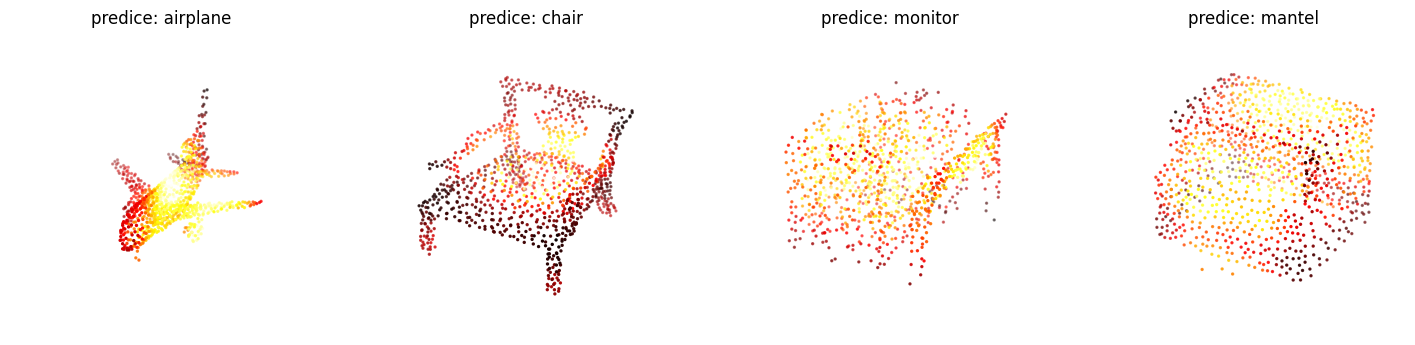

In [ ]:
fig = plt.figure(figsize=(18, 4.5))
for k, i in enumerate(ejemplos[:4]):
    imp, c = donde_mira(Xte[i])
    p = Xte[i].cpu()
    ax = fig.add_subplot(1, 4, k + 1, projection="3d"); ax.set_axis_off()
    ax.scatter(p[:, 0], p[:, 2], p[:, 1], s=2, c=imp, cmap="hot")
    ax.set_title(f"predice: {CLASES[c]}")
plt.show()

## **4.- CNN 3D dispersa con spconv**
 hacemos lo mismo que la CNN densa, pero con una red dispersa a 64³: en lugar de procesar toda la grilla, procesa solo los vóxeles ocupados, y se compara su exactitud, tiempo y memoria con la densa

---
**Recordatorio**
Usaremos **spconv**:
* es una librería para PyTorch que hace convoluciones 3D solo donde hay datos
* una CNN 3D normal recorre todos los cubos de la grilla, incluso los vacíos, y en una escena real más del 99 % está vacía
* spconv guarda solo la lista de cubos ocupados, con su posición y su valor, y calcula únicamente sobre ellos
* asi gastamos mucha menos memoria y tiempo, y permite usar grillas más finas

usaremos dos tipos de capa:

* SubMConv3d: convoluciona solo sobre los cubos ocupados y no crea cubos nuevos, así que la forma del objeto no se “infla”
* SparseConv3d con stride 2: reduce la resolución a la mitad, como un pooling
---

esta función convierte puntos en una lista de vóxeles ocupados (no en una grilla)

In [ ]:
def a_disperso(P, R):
    i = ((P + 1) / 2 * R).long().clamp(0, R - 1) # en qué cubo cae cada punto, igual que en voxelizar pero con R = 64.
    b = torch.arange(len(P), device=P.device)[:, None, None].expand(-1, P.shape[1], 1) # a qué objeto del lote pertenece cada punto
    idx = torch.cat([b, i], -1).reshape(-1, 4).unique(dim=0).int() # junta [objeto, i, j, k], hace una lista y borra repetidos
    return spconv.SparseConvTensor(torch.ones(len(idx), 1, device=P.device), idx, [R, R, R], len(P)) # tensor disperso: feature 1 en cada vóxel ocupado

esta función procesa y luego reduce la resolución:
* SubMConv3: es conv 3×3×3 solo en los cubos ocupados, la salida tiene exactamente los mismos cubos, equivale a	Conv3d
* BatchNorm1d + ReLU:	normaliza y activa, es 1d porque los datos son una lista, no una grilla, equivale a	BatchNorm3d + ReLU
* SparseConv3d(stride=2): conv que reduce la resolución a la mitad, equivale a MaxPool3d(2)

In [ ]:
def bloque_disperso(cin, cout, clave):
    return [spconv.SubMConv3d(cin, cout, 3, indice_key=clave),
            nn.BatchNorm1d(cout),
            nn.ReLU(),
            spconv.SparseConv3d(cout, cout, 3, stride=2, padding=1),
            nn.BatchNorm1d(cout),
            nn.ReLU()]

tres bloques: 64³ -> 32³ -> 16³ -> 8³

In [ ]:
cnn_disp = spconv.SparseSequential(*bloque_disperso(1, 32, "a"),
                                   *bloque_disperso(32, 64, "b"),
                                   *bloque_disperso(64, 128, "c")).cuda()

clasificador final a 40 clases

In [ ]:
cabeza = nn.Sequential(nn.Dropout(0.5), nn.Linear(128, 40)).cuda()

recibe puntos y devuelve la predicción de cada objeto

In [ ]:
def dispersa(P):
    x = cnn_disp(a_disperso(P, 64)) # pasa los vóxeles ocupados a 64³ por la red dispersa
    g = torch.full((len(P), 128), -1e9, device="cuda").index_reduce(0, x.indices[:, 0].long(), x.features, "amax")  # máximo de cada canal por objeto (pooling global)
    return cabeza(g) # clasifica los 128 valores de cada objeto

prueba con un lote de 32 objetos

In [ ]:
x = a_disperso(Xtr[:32], 64)
print(f"lote de 32 objetos a 64³: {len(x.indices):,} vóxeles ocupados de {32 * 64**3:,}")  # muestra cuántos vóxeles procesa en verdad frente al total
entrenar(dispersa, nn.ModuleList([cnn_disp, cabeza]))   # entrena con la misma función, ModuleList junta los pesos de las dos partes

W1103 15:19:58.833000 643 torch/fx/_symbolic_trace.py:53] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.


lote de 32 objetos a 64³: 32,573 vóxeles ocupados de 8,388,608


/tmp/ipykernel_643/2936143093.py:3: UserWarning: index_reduce() is in beta and the API may change at any time. (Triggered internally at /pytorch/aten/src/ATen/native/cuda/Indexing.cu:1469.)
  g = torch.full((len(P), 128), -1e9, device="cuda").index_reduce(0, x.indices[:, 0].long(), x.features, "amax")  # máximo de cada canal por objeto (pooling global)


época  1 | accuracy test 0.324
época  2 | accuracy test 0.539
época  3 | accuracy test 0.652
época  4 | accuracy test 0.713
época  5 | accuracy test 0.741
época  6 | accuracy test 0.776
época  7 | accuracy test 0.773
época  8 | accuracy test 0.811
época  9 | accuracy test 0.822
época 10 | accuracy test 0.821
época 11 | accuracy test 0.816
época 12 | accuracy test 0.831
época 13 | accuracy test 0.840
época 14 | accuracy test 0.850
época 15 | accuracy test 0.842
11.0 s por época | memoria máxima 344 MB


La red dispersa trabaja al doble de resolución (64³, 8 veces más vóxeles) y aun así usa menos memoria, porque solo calcula donde hay datos. Como no hay grilla, el pooling global se hace con index_reduce, que toma el máximo por objeto. Por eso VoxelNet, SECOND y CenterPoint usan convoluciones dispersas.

**Limitación**: voxelizar pierde el detalle dentro de cada cubo. Las convoluciones dispersas resuelven la memoria, no ese detalle.